In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [5]:
df = pd.read_pickle('../../../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')

In [6]:
TRACT_RICH = 1700
TRACT_POOR = 2104
TRACT_MIDDLE = 1802
# 建议统一成可比较的整数（避免 float / 字符串）
t = pd.to_numeric(df["tractID"], errors="coerce").astype("Int64")
df_tract_rich = df.loc[t == TRACT_RICH].copy()
df_tract_poor = df.loc[t == TRACT_POOR].copy()
df_tract_middle = df.loc[t == TRACT_MIDDLE].copy()

In [7]:
import re
import numpy as np
import pandas as pd

# 与原来一致：EXPECTED_DAYS = 31, value_cols, N_COLS 已在前面定义

# 2018-10 共 31 个日历日（按日对齐）
OCT_FULL_INDEX = pd.date_range("2018-10-01", "2018-10-31", freq="D")
EXPECTED_DAYS = 31
value_cols = sorted(
    [c for c in df_tract_rich.columns if re.match(r"INT_VALUE_\d{4}", c)],
    key=lambda c: int(c.split("_")[-1]),
)
N_COLS = EXPECTED_DAYS * len(value_cols)  # 31 * 48 = 1488

MIN_DAYS = 29  # 缺最多 2 天 → 至少 29 天有数；缺失天用 0 补齐


def tract_to_october_hour_wide(tract_df: pd.DataFrame) -> pd.DataFrame:
    """
    10 月内 (badge,date) 去重后：
      - 不同日期数 < 29 的户丢弃；
      - 29/30/31 天保留，缺的天在全日 48 列上填 0，再拼成 31×48。
    """
    d = tract_df.loc[
        (tract_df["date"] >= "2018-10-01") & (tract_df["date"] <= "2018-10-31")
    ].copy()
    if d.empty:
        return pd.DataFrame(columns=["badge"] + [f"oct_h{i:04d}" for i in range(N_COLS)])

    d["date"] = pd.to_datetime(d["date"], errors="coerce").dt.normalize()
    d = d.drop_duplicates(subset=["badge", "date"], keep="first")

    rows = []
    for badge, g in d.groupby("badge"):
        n = g["date"].nunique()
        if n < MIN_DAYS:
            continue

        g = g.set_index("date").sort_index()
        g = g.reindex(OCT_FULL_INDEX)
        g[value_cols] = g[value_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0)

        flat = g[value_cols].to_numpy(dtype=float, copy=False).ravel()
        if flat.size != N_COLS:
            raise ValueError(f"badge {badge}: 展平长度 {flat.size}，期望 {N_COLS}")
        rows.append(np.concatenate(([badge], flat)))

    col_names = ["badge"] + [f"oct_h{i:04d}" for i in range(N_COLS)]
    return pd.DataFrame(rows, columns=col_names)


df_tract_rich_half_hour = tract_to_october_hour_wide(df_tract_rich)
df_tract_poor_half_hour = tract_to_october_hour_wide(df_tract_poor)
df_tract_middle_half_hour = tract_to_october_hour_wide(df_tract_middle)

In [8]:
import numpy as np

def add_row_missing_and_zero_ratio(df: pd.DataFrame, col_prefix: str = "oct_h") -> pd.DataFrame:
    out = df.copy()
    val_cols = [c for c in out.columns if c.startswith(col_prefix)]
    if not val_cols:
        raise ValueError("未找到半点列（默认 oct_h 前缀）")

    X = out[val_cols].to_numpy(dtype=float, copy=False)

    out["halfhour_missing_ratio"] = np.isnan(X).mean(axis=1)
    out["halfhour_zero_ratio"] = np.mean(X == 0, axis=1)   # 含 NaN 的格子里，(X==0) 为 False
    return out


df_tract_rich_half_hour = add_row_missing_and_zero_ratio(df_tract_rich_half_hour)
df_tract_poor_half_hour = add_row_missing_and_zero_ratio(df_tract_poor_half_hour)
df_tract_middle_half_hour = add_row_missing_and_zero_ratio(df_tract_middle_half_hour)

In [9]:
THRESH = 0.15  # 15%
df_tract_rich_half_hour = df_tract_rich_half_hour.loc[
    df_tract_rich_half_hour["halfhour_zero_ratio"] < THRESH
].copy()
df_tract_poor_half_hour = df_tract_poor_half_hour.loc[
    df_tract_poor_half_hour["halfhour_zero_ratio"] < THRESH
].copy()
df_tract_middle_half_hour = df_tract_middle_half_hour.loc[
    df_tract_middle_half_hour["halfhour_zero_ratio"] < THRESH
].copy()

In [10]:
print(df_tract_rich_half_hour['badge'].nunique())
print(df_tract_poor_half_hour['badge'].nunique())
print(df_tract_middle_half_hour['badge'].nunique())

1053
528
1122


In [11]:
import re
import numpy as np
import pandas as pd

DAYS = 31
HALF_PER_DAY = 48
BLOCKS_PER_DAY = 6    # 每天 6 个 4 小时块
HALF_PER_BLOCK = 8    # 每块 8 个半小时

def oct_h_sorted_columns(df: pd.DataFrame, prefix: str = "oct_h") -> list[str]:
    cols = [c for c in df.columns if c.startswith(prefix)]
    return sorted(cols, key=lambda c: int(re.search(r"oct_h(\d+)", c).group(1)))

def half_hour_wide_to_four_hour(
    df: pd.DataFrame,
    meta_cols: list[str] | None = None,
    oct_prefix: str = "oct_h",
    out_prefix: str = "oct_4h",
) -> pd.DataFrame:
    """
    宽表：badge + oct_h*（1488） → badge + meta + oct_4h*（186）
    每个 4 小时块 = 当日连续 8 个半点之和。
    """
    cols = oct_h_sorted_columns(df, oct_prefix)
    if len(cols) != DAYS * HALF_PER_DAY:
        raise ValueError(f"期望 {DAYS * HALF_PER_DAY} 个半点列，实际 {len(cols)}")

    if meta_cols is None:
        meta_cols = [c for c in df.columns if not c.startswith(oct_prefix)]

    X = df[cols].to_numpy(dtype=float)
    n = X.shape[0]
    Xd = X.reshape(n, DAYS, HALF_PER_DAY)
    X4h = Xd.reshape(n, DAYS, BLOCKS_PER_DAY, HALF_PER_BLOCK).sum(axis=-1)
    flat = X4h.reshape(n, DAYS * BLOCKS_PER_DAY)
    out_cols = [f"{out_prefix}_{i:04d}" for i in range(DAYS * BLOCKS_PER_DAY)]
    out_num = pd.DataFrame(flat, columns=out_cols, index=df.index)
    meta = df[meta_cols].copy()
    return pd.concat([meta, out_num], axis=1)

META = ["badge", "halfhour_missing_ratio", "halfhour_zero_ratio"]
META = [c for c in META if c in df_tract_rich_half_hour.columns]

df_tract_rich_four_hour = half_hour_wide_to_four_hour(
    df_tract_rich_half_hour.rename(columns={}),
    meta_cols=META,
)
df_tract_poor_four_hour = half_hour_wide_to_four_hour(
    df_tract_poor_half_hour,
    meta_cols=[c for c in META if c in df_tract_poor_half_hour.columns],
)
df_tract_middle_four_hour = half_hour_wide_to_four_hour(
    df_tract_middle_half_hour,
    meta_cols=[c for c in META if c in df_tract_middle_half_hour.columns],
)

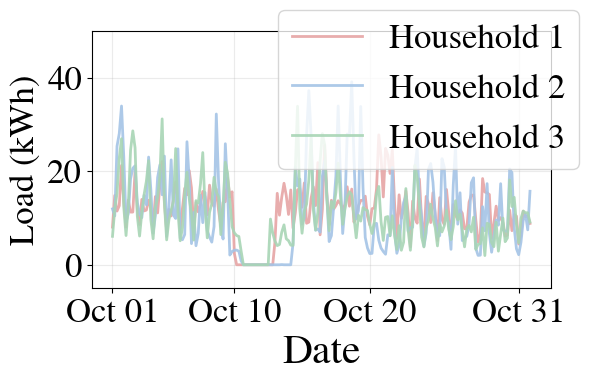

In [13]:
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

def oct_4h_columns(df: pd.DataFrame, prefix: str = "oct_4h") -> list[str]:
    cols = [c for c in df.columns if c.startswith(prefix)]
    return sorted(cols, key=lambda c: int(re.search(r"oct_4h_(\d+)", c).group(1)))

def plot_tract_sample_curves_four_hour(
    df: pd.DataFrame,
    title: str,
    n: int = 10,
    random_state=0,
    alpha: float = 0.9,
    lw: float = 2,
    colors=None,
):
    cols = oct_4h_columns(df)
    if not cols:
        raise ValueError("未找到 oct_4h 列")

    n_draw = min(n, len(df))
    if n_draw == 0:
        print(f"[{title}] 无数据，跳过")
        return

    samp = df.sample(n=n_draw, random_state=random_state).reset_index(drop=True)
    X = samp[cols].to_numpy(dtype=float)

    # 2018年10月，每4小时一个点
    x = pd.date_range(
        start="2018-10-01 00:00",
        periods=X.shape[1],
        freq="4h"
    )

    if colors is None:
        colors = [
            "#E6A4A4",
            "#A4C4E6",
            "#A8D5B5",
            "#E8D4B8",
            "#C4B7D4",
        ]

    fig, ax = plt.subplots(figsize=(6, 4))

    for i, row in enumerate(X):
        ax.plot(
            x,
            row,
            color=colors[i % len(colors)],
            alpha=alpha,
            lw=lw,
            label=f"Household {i + 1}",
        )

    ax.set_xlabel("Date", fontsize=30)
    ax.set_ylabel("Load (kWh)", fontsize=25)

    # 只显示三个日期
    tick_dates = pd.to_datetime([
        "2018-10-01",
        "2018-10-10",
        "2018-10-20",
        "2018-10-31",
    ])
    ax.set_xticks(tick_dates)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

    ax.set_ylim(-5, 50)

    ax.tick_params(axis="x", labelsize=25)
    ax.tick_params(axis="y", labelsize=25)

    ax.legend(loc="upper right",bbox_to_anchor=(1.10, 1.15), fontsize=25)
    ax.grid(True, alpha=0.25)

    
    plt.tight_layout()
    plt.savefig(f"../../../Analysis/Plot/Motivation/household_visualization.png", dpi=300)
    plt.show()

N = 3
RNG = 5
plot_tract_sample_curves_four_hour(
    df_tract_rich_four_hour, "Tract rich (1700)", n=N, random_state=RNG
)
# plot_tract_sample_curves_four_hour(
#     df_tract_poor_four_hour, "Tract poor (2104)", n=N, random_state=RNG
# )
# plot_tract_sample_curves_four_hour(
#     df_tract_middle_four_hour, "Tract middle (1802)", n=N, random_state=RNG
# )

# 4